In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/amazon-uk-products-dataset-2023")

print("Path to dataset files:", path)
#Path to dataset files: C:\Users\M. Grillo\.cache\kagglehub\datasets\asaniczka\amazon-uk-products-dataset-2023\versions\33

Path to dataset files: C:\Users\M. Grillo\.cache\kagglehub\datasets\asaniczka\amazon-uk-products-dataset-2023\versions\33


In [22]:
import pandas as pd

df = pd.read_csv("../datasets/amz_uk_price_prediction_dataset.csv")

In [24]:
num = df.select_dtypes(include="number")
cat = df.select_dtypes(exclude="number")

#cat['categoryName']

In [26]:
for i in range(0, 5):
    print(cat['category'].value_counts().index[i])

Sports & Outdoors
Beauty
Handmade Clothing, Shoes & Accessories
Bath & Body
Birthday Gifts


In [27]:
#df.columns
vc = df['category'].value_counts()
vc5 = df['category'].value_counts().head(5)
#vc5.iloc[0]
#vc5.iloc[1]
#vc5.iloc[3]
#vc5.iloc[1] #  vc5.iloc[0] -> np.int64(826076)
vc5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

<Axes: xlabel='category'>

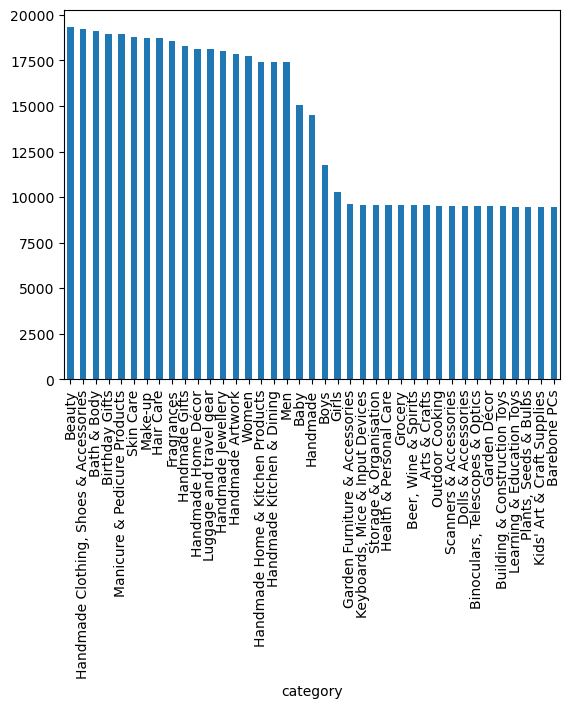

In [28]:
# Sports & Outdoors dominates the listing
import matplotlib.pyplot as plt
#vc5.plot.bar()
plt.show()
vc2ndWinners = vc.iloc[1:40]
vc2ndWinners.plot.bar()

<Axes: ylabel='count'>

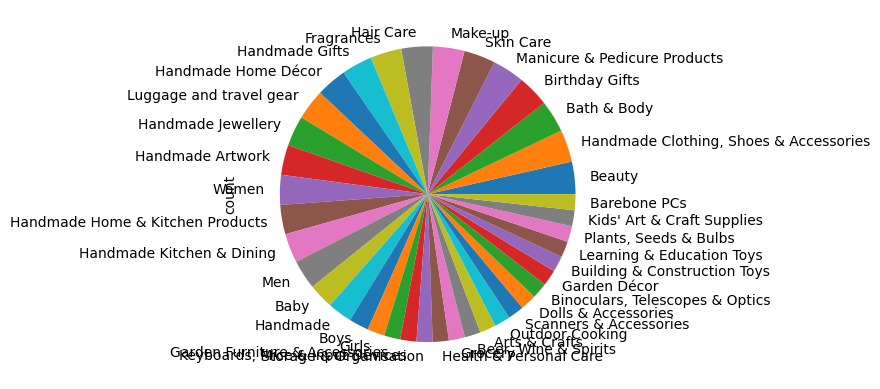

In [ ]:
vc2ndWinners.plot.pie()
#this looks like candy to my eyes!

<Axes: ylabel='count'>

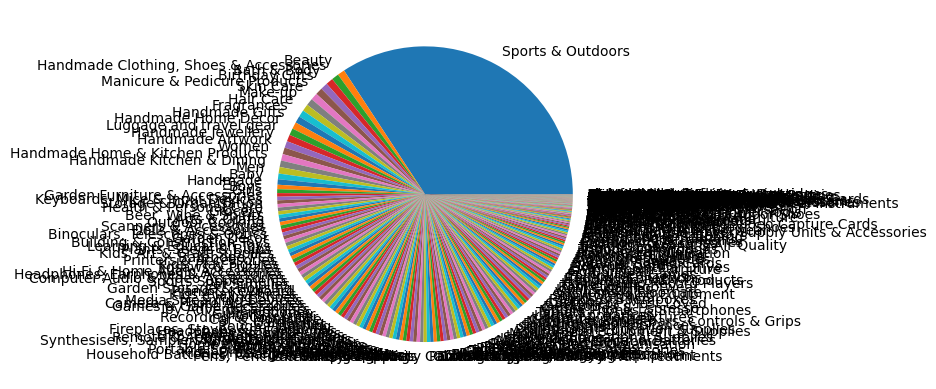

In [30]:
vc.plot.pie()
#as this isn't completely bad eather - first 40 rows are allready too much for the chart

In [31]:
vc2ndWinners.mode()
vc2ndWinners[20:40]

category
Boys                               11789
Girls                              10310
Garden Furniture & Accessories      9626
Keyboards, Mice & Input Devices     9597
Storage & Organisation              9569
Health & Personal Care              9569
Grocery                             9564
Beer, Wine & Spirits                9553
Arts & Crafts                       9549
Outdoor Cooking                     9532
Scanners & Accessories              9532
Dolls & Accessories                 9511
Binoculars, Telescopes & Optics     9497
Garden Décor                        9492
Building & Construction Toys        9490
Learning & Education Toys           9487
Plants, Seeds & Bulbs               9482
Kids' Art & Craft Supplies          9482
Barebone PCs                        9478
Name: count, dtype: int64

###############
### Part 2: Delving into Product Pricing

In [33]:
print(f"{df.price.mean()}     {df.price.median()}     {df.price.mode()[0]}")

89.24380943923661     19.09     9.99


In [34]:
print(f"standard deviation: {df.price.std()} - which I think is huge; median: {df.price.median()} is much lower than average: {df.price.mean()} --> some products are extremely expensive." )

standard deviation: 345.60886175352226 - which I think is huge; median: 19.09 is much lower than average: 89.24380943923661 --> some products are extremely expensive.


In [35]:
#Determine the variance, standard deviation, range, and interquartile range for product `price`.
q1 = df.price.quantile(0.25)
q2 = df.price.quantile(0.50)
q3 = df.price.quantile(0.75)
variance = df.price.var()
std = df.price.std()
range_ = df.price.max() - df.price.min()
iqr = q3 - q1

print(f"variance: {variance} ; std: {std} ; range: {range_} ; Q1: {q1} ; median: {q2} ; Q3: {q3} ; IQR: {iqr}")

variance: 119445.48532256528 ; std: 345.60886175352226 ; range: 100000.0 ; Q1: 9.99 ; median: 19.09 ; Q3: 45.99 ; IQR: 36.0


In [37]:
df.price.max()

100000.0

3. **Visualizations**:

In [63]:

plt.show()
df_filtered = df[df["price"] < q3 + 99]
df_f2 = df_filtered
print(df.shape)
df.shape
#[df_filtered["price"] > 0.01]

print (df.shape[0] - df_f2.shape[0])

(2443651, 9)
251542


<Axes: ylabel='Frequency'>

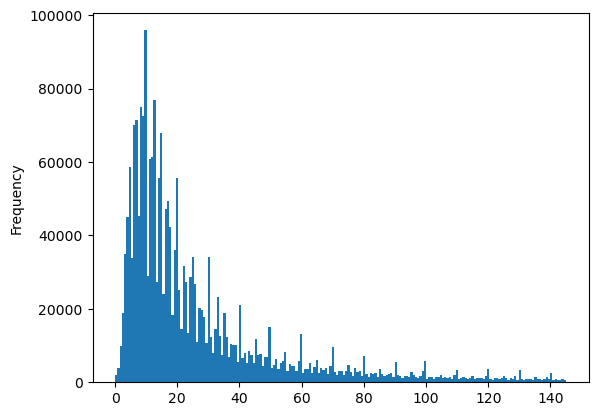

In [39]:
#df.price.plot.box()


df_f2.price.plot.hist(bins=200)





In [41]:
251542/2443651

0.10293695785527475

the main part shrinks in viszualization because of the large values for few huge prices. To cut them off I suggest q3 + 99 as limit.

That cuts off 238943 of 2222742 of products / prices (bit more than 10%).

### Part 3: Unpacking Product Ratings
1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [71]:
#df.columns
#df.groupby('title')['stars'].sum().sort_values(ascending=False).head(12)
#df.stars.value_counts().head(1)
mmean = df.groupby('title')['stars'].mean()
mmedian = df.groupby('title')['stars'].median()[0]
mmode= df.groupby('title')['stars'].value_counts().head(1)
mmean
mmedian
mmode




C:\Users\M. Grillo\AppData\Local\Temp\ipykernel_24468\3765750168.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  mmedian = df.groupby('title')['stars'].median()[0]


title                                                                                                                                              stars
6 Pack of 225ml Lynx 12 Hour Refreshing Excite Crisp Coconut and Black Pepper Body wash for Feeling Clean and Fresh with Plant-based Moisturisers  4.7      1
Name: count, dtype: int64

stars
0.0    1225641
Name: count, dtype: int64

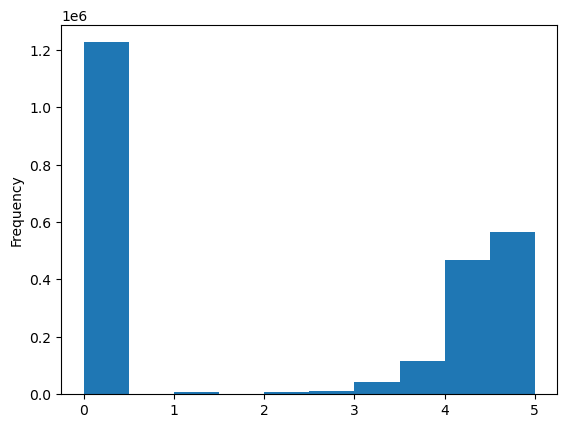

In [72]:
df.columns
df.stars.plot.hist()
df.stars.value_counts().head(1)

People rate 0 stars a lot.
Then they tend to give 5 stars desc. 3,2 and 1 stars are given fewly.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [73]:
dn = df[df['stars'] > 0]

varrn = dn.stars.var()
stddn = dn.stars.std()
q1n = dn.stars.quantile(0.25)
q2n = dn.stars.quantile(0.50)
q3n = dn.stars.quantile(0.75)

print(f"variance: {varrn} ; std: {stddn} ; Q1: {q1n} ; median: {q2n} ; Q3: {q3n} ")


varr = df.stars.var()
stdd = df.stars.std()
q1 = df.stars.quantile(0.25)
q2 = df.stars.quantile(0.50)
q3 = df.stars.quantile(0.75)

print(f"variance: {varr} ; std: {stdd} ; Q1: {q1} ; median: {q2} ; Q3: {q3} ")


variance: 0.3083433752380519 ; std: 0.5552867504614637 ; Q1: 4.1 ; median: 4.4 ; Q3: 4.6 
variance: 4.81743402976196 ; std: 2.1948653785054697 ; Q1: 0.0 ; median: 0.0 ; Q3: 4.4 


more than half of the stars are 0, because median = 0.

If we would filter out all ratings equal to 0, sdt deviation would be 0.56 around 4.4.


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?
    

In [75]:
df.stars.skew()

np.float64(0.08120735761080881)

In [78]:
#dn.stars.skew()
df.stars.kurt()

np.float64(-1.9260061280432994)

We have 2 modes on both sides of the range. Looks statistically like equal distribution in some measurements.

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


<Axes: ylabel='Frequency'>

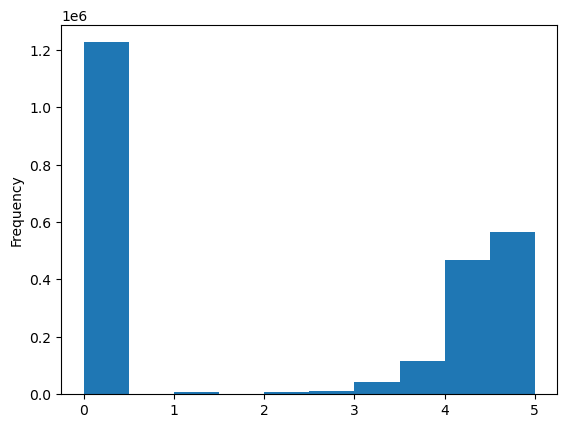

In [79]:
df.stars.plot.hist()